In [1]:
import os
import sys
import tempfile
from pathlib import Path
from IPython.display import Image, display

# The notebook starts in docs/examples. Keep generated files outside the checkout.
repository = Path.cwd().parents[1]
workspace = tempfile.TemporaryDirectory(prefix="croak-gallery-")
(Path(workspace.name) / "examples").symlink_to(repository / "examples", target_is_directory=True)
sys.path.insert(0, str(repository / "examples"))
os.chdir(workspace.name)

In [2]:
"""Synthetic DUV TG-FROG trace carrying interferometric fringes and a leakage shelf.

Shared by :mod:`example_defringe` and :mod:`example_arpls_baseline`, which
demonstrate the two cleaning steps that a measured deep-ultraviolet
transient-grating FROG trace usually needs. Both are imported by filename from
the ``examples/`` directory, which Python puts on ``sys.path`` when it runs a
script from there.

The measurement model
---------------------
In a TG/PG geometry the spectrometer sees the signal field :math:`E_s` on top of
a leakage field :math:`E_b` — scattered pump light, or an imperfectly blocked
beam — that reaches the detector with a delay-dependent amplitude. The two
interfere, so the recorded trace is

.. math::

    I(\\lambda,\\tau) = |E_s|^2 + |E_b|^2
        + 2\\,|E_s|\\,|E_b|\\,\\cos\\!\\big(2\\pi f_c(\\lambda)\\,\\tau + \\phi\\big),

with the optical carrier :math:`f_c(\\lambda) = c/\\lambda`. That gives the three
components the cleaning chain has to separate:

* ``signal`` — :math:`|E_s|^2`, the FROG trace we actually want;
* ``baseline`` — :math:`|E_b|^2`, a broad shelf, **asymmetric** in delay
  (strong at negative delay, weak at positive), removed by
  :func:`croak.preprocess.arpls_baseline`;
* the cosine cross term — the diagonal fringes, removed by
  :func:`croak.preprocess.defringe_carrier`, which keeps only the DC band below
  :math:`f_c`.

Because each component is known exactly here, the examples can report the
actual recovery error, not only that the cleaning ran.

Sampling
--------
Resolving the fringes requires a delay step finer than half the carrier period,
:math:`\\delta\\tau < \\lambda/(2c)` — about 0.42 fs at 250 nm, far finer than a
FROG scan needs for the signal itself. Under-sampling folds the carrier back
below the Nyquist frequency and :func:`~croak.preprocess.defringe_carrier` then
refuses to run (``on_alias="raise"``). :data:`DELAY_STEP` is chosen with margin.
"""

from __future__ import annotations

from dataclasses import dataclass

import numpy as np
from numpy.typing import NDArray

import croak
from croak.constants import C
from croak.maths import wlfreq

__all__ = ["FringedTrace", "DELAY_STEP", "CARRIER_WAVELENGTH", "make_fringed_trace"]

#: Carrier wavelength of the synthetic DUV pulse (m).
CARRIER_WAVELENGTH = 250e-9

#: Delay step (s). Must satisfy dtau < lambda/(2c) ≈ 0.42 fs at 250 nm for the
#: fringe carrier to stay below the delay Nyquist frequency; 0.15 fs leaves a
#: factor ~2.8 of margin, which also covers the blue edge of the signal band.
DELAY_STEP = 0.15e-15


@dataclass(frozen=True)
class FringedTrace:
    """A synthetic measured trace together with the components it was built from.

    Attributes
    ----------
    lam : numpy.ndarray
        Wavelength axis (m), ascending, shape ``(Nlambda,)``.
    tau : numpy.ndarray
        Delay axis (s), uniform, shape ``(Ndelay,)``.
    measured : numpy.ndarray
        What the spectrometer records: ``signal + baseline + fringes``,
        shape ``(Nlambda, Ndelay)``.
    magnitude : numpy.ndarray
        The fringe-free magnitude trace ``signal + baseline`` — the exact target
        of :func:`croak.preprocess.defringe_carrier`.
    signal : numpy.ndarray
        The clean FROG trace ``|E_s|^2`` — the exact target of the full
        de-fringe-then-baseline chain.
    baseline : numpy.ndarray
        The leakage background ``|E_b|^2``.
    """

    lam: NDArray[np.float64]
    tau: NDArray[np.float64]
    measured: NDArray[np.float64]
    magnitude: NDArray[np.float64]
    signal: NDArray[np.float64]
    baseline: NDArray[np.float64]


def make_fringed_trace(
    *,
    fwhm: float = 5e-15,
    gdd: float = 8e-30,
    tau_max: float = 45e-15,
    baseline_amplitude: float = 0.35,
    fringe_visibility: float = 0.9,
    seed: int = 0,
) -> FringedTrace:
    """Build a synthetic fringed, background-contaminated DUV TG-FROG trace.

    Parameters
    ----------
    fwhm : float, optional
        Intensity FWHM of the underlying pulse (s). Default ``5e-15``.
    gdd : float, optional
        Group-delay dispersion applied to the pulse (s²), so the trace is
        visibly chirped. Default ``8e-30``.
    tau_max : float, optional
        Half-range of the delay scan (s); the axis spans ``[-tau_max, tau_max]``
        in steps of :data:`DELAY_STEP`. Wide enough that the broad leakage
        background decays to zero inside the scan. Default ``45e-15``.
    baseline_amplitude : float, optional
        Peak of the leakage shelf as a fraction of the signal peak. Default
        ``0.35``.
    fringe_visibility : float, optional
        Fringe contrast in ``[0, 1]``; the cross term is scaled by this times
        its maximum possible value ``2|E_s||E_b|``. Default ``0.9``.
    seed : int, optional
        Seed for the small amount of additive shot-like noise. Default ``0``.

    Returns
    -------
    FringedTrace
        The measured trace and each of its exact components.
    """
    omega0 = wlfreq(CARRIER_WAVELENGTH)

    # A grid whose time window comfortably exceeds the delay range plus the pulse,
    # so the gated signal never wraps around the periodic FFT window.
    grid = croak.Grid(256, dt=0.35e-15)
    ew = croak.gaussian_pulse(grid, fwhm, phases=[gdd])

    tau = np.arange(-tau_max, tau_max + 0.5 * DELAY_STEP, DELAY_STEP)
    # PG (transient-grating) is degenerate: the signal sits at the fundamental
    # wavelength, so the trace band is centred on CARRIER_WAVELENGTH.
    trace_omega = croak.maketrace(grid.omega, tau, ew, "pg")

    # Baseband angular frequency -> absolute -> wavelength, keeping only the
    # physical band and sorting to the ascending-lambda order a spectrometer
    # reports. Mirrors examples/example_workflow.py.
    omega_abs = grid.omega + omega0
    band = (omega_abs > 0.65 * omega0) & (omega_abs < 1.45 * omega0)
    lam = wlfreq(omega_abs[band])
    order = np.argsort(lam)
    lam = lam[order]
    signal = trace_omega[band][order, :]
    signal = signal / signal.max()

    # Leakage background |E_b|^2: separable in wavelength and delay. Spectrally it
    # is broader than the signal (scattered light is not gated, so it carries the
    # full pump bandwidth); in delay it is a broad, *skewed* bump — rising slowly
    # on the early side and falling faster once the beams separate. That is the
    # asymmetry arPLS has to follow, and unlike a step it decays at both ends of
    # the scan, so the trace stays smooth across the periodic FFT boundary.
    lam_profile = signal.sum(axis=1)
    lam_profile = lam_profile / lam_profile.max()
    # Broaden by convolving with a Gaussian a few samples wide.
    kernel = np.exp(-0.5 * (np.arange(-12, 13) / 5.0) ** 2)
    lam_profile = np.convolve(lam_profile, kernel / kernel.sum(), mode="same")
    lam_profile = lam_profile / lam_profile.max()
    # Much broader than the ~7 fs signal: the leakage is not gated by the pulse
    # overlap, so it varies on the beam-crossing scale. That scale separation is
    # exactly what lets arPLS tell background from signal.
    tau_centre, width_early, width_late = -12e-15, 22e-15, 12e-15
    width = np.where(tau < tau_centre, width_early, width_late)
    shelf = np.exp(-0.5 * ((tau - tau_centre) / width) ** 2)
    baseline = baseline_amplitude * lam_profile[:, None] * shelf[None, :]

    # Interferometric cross term at the per-wavelength optical carrier. The
    # geometric mean 2|E_s||E_b| is the largest a real interference term can be,
    # so fringe_visibility <= 1 keeps the trace non-negative.
    carrier = C / lam  # ordinary frequency f_c (Hz), one per wavelength row
    phase = 2.0 * np.pi * carrier[:, None] * tau[None, :]
    fringes = fringe_visibility * 2.0 * np.sqrt(signal * baseline) * np.cos(phase)

    magnitude = signal + baseline
    rng = np.random.default_rng(seed)
    noise = rng.normal(0.0, 2e-4, size=magnitude.shape)
    measured = np.clip(magnitude + fringes + noise, 0.0, None)

    return FringedTrace(
        lam=lam,
        tau=tau,
        measured=measured,
        magnitude=magnitude,
        signal=signal,
        baseline=baseline,
    )


In [3]:
"""De-fringe a DUV TG-FROG trace (Takeda FTSI).

Builds a synthetic deep-ultraviolet transient-grating FROG trace that carries
interferometric fringes on top of the signal (see :mod:`synthetic_duv_trace`),
then removes them with :func:`croak.preprocess.defringe_carrier` — a smooth
per-wavelength low-pass that keeps the slow magnitude band below the optical
carrier ``f_c(λ) = c/λ`` and discards the ``±f_c`` sidebands. Run::

    uv run python examples/example_defringe.py

Because the trace is synthetic, the fringe-free magnitude ``a = |E_s|² + |E_b|²``
is known exactly, so the example reports the *actual* recovery error rather than
only showing that something happened. Writes ``defringe_check.png``; read it as:

* **residual** (measured − de-fringed) should be the diagonal fringe pattern
  *only* — any slow envelope leaking in means ``CARRIER_FRACTION`` is too low;
* **row cuts** — the thick de-fringed curve should ride the centre of the
  measured oscillation and sit on the dashed truth;
* **delay / wavelength marginals** should overlay (signal preserved, only the
  zero-mean fringe removed).

Note the de-fringed trace still contains the broad leakage background |E_b|²;
removing that is a separate step, shown in ``example_arpls_baseline.py``.
"""

from __future__ import annotations

import matplotlib
import numpy as np

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from synthetic_duv_trace import make_fringed_trace

from croak.preprocess import defringe_carrier

# De-fringe cutoff as a fraction of the carrier f_c = c/λ (in (0, 1)). It must
# sit above the trace's own slow delay-bandwidth and below the fringe carrier;
# anywhere in ~0.3–0.6 works here, and the recovery error is insensitive to it.
CARRIER_FRACTION = 0.5


def main() -> None:
    """Build the fringed trace, de-fringe it and write the comparison figure."""
    ft = make_fringed_trace()

    # The DUV carrier (≈0.83 fs period at 250 nm) needs δτ < λ/(2c) to avoid
    # aliasing. synthetic_duv_trace.DELAY_STEP satisfies this with margin, so the
    # default on_alias="raise" is the right setting: on real data a raise here
    # means the scan was stepped too coarsely to separate the fringes at all.
    defr = defringe_carrier(
        ft.measured, ft.lam, ft.tau, carrier_fraction=CARRIER_FRACTION
    )

    peak = ft.magnitude.max()
    print(f"trace: {ft.lam.size} wavelengths × {ft.tau.size} delays")
    print(
        f"max error vs true magnitude: {np.abs(defr - ft.magnitude).max() / peak:.2%}"
    )
    print(f"RMS error vs true magnitude: {np.std(defr - ft.magnitude) / peak:.2%}")

    _plot(ft, defr)


def _plot(ft, defr) -> None:
    """Six-panel measured-vs-defringed diagnostic; writes ``defringe_check.png``."""
    tau_fs = ft.tau / 1e-15
    lam_nm = ft.lam / 1e-9
    trace = ft.measured

    # Zoom the 2-D maps to the signal-bearing wavelength band (with a margin), so
    # the compact signal and the diagonal fringes are not a thin strip.
    marg_lam = trace.sum(axis=1)
    sig = np.where(marg_lam > 0.05 * marg_lam.max())[0]
    lo, hi = lam_nm[sig[0]], lam_nm[sig[-1]]
    pad = 0.25 * (hi - lo)
    band = (lam_nm >= lo - pad) & (lam_nm <= hi + pad)
    vmax = float(trace[band].max())

    fig, ax = plt.subplots(2, 3, figsize=(15, 8))

    ax[0, 0].pcolormesh(tau_fs, lam_nm, trace, shading="auto", vmin=0, vmax=vmax)
    ax[0, 0].set_title("measured (fringed)")
    ax[0, 0].set_ylabel("λ (nm)")
    ax[0, 1].pcolormesh(tau_fs, lam_nm, defr, shading="auto", vmin=0, vmax=vmax)
    ax[0, 1].set_title("de-fringed a(λ,τ)")
    rvmax = float(np.abs((trace - defr)[band]).max())
    ax[0, 2].pcolormesh(
        tau_fs,
        lam_nm,
        trace - defr,
        shading="auto",
        cmap="RdBu_r",
        vmin=-rvmax,
        vmax=rvmax,
    )
    ax[0, 2].set_title("residual = measured − de-fringed (the fringes)")
    for a in ax[0]:
        a.set_ylim(lo - pad, hi + pad)
        a.set_xlabel("delay (fs)")

    # Row cuts at the three brightest signal wavelengths, against the known truth.
    rows = np.argsort(trace.sum(axis=1))[-3:]
    for n, i in enumerate(rows):
        (line,) = ax[1, 0].plot(tau_fs, trace[i], lw=0.7, alpha=0.4)
        ax[1, 0].plot(
            tau_fs, defr[i], lw=1.6, color=line.get_color(), label=f"{lam_nm[i]:.0f} nm"
        )
        # One legend entry for the truth, not one per row — they are all black.
        ax[1, 0].plot(
            tau_fs,
            ft.magnitude[i],
            "--",
            lw=1.0,
            color="k",
            label="true" if n == 0 else None,
        )
    ax[1, 0].set_title("row cuts: measured (thin) · de-fringed (thick) · true (dashed)")
    ax[1, 0].set_xlabel("delay (fs)")
    ax[1, 0].legend(fontsize=7)

    ax[1, 1].plot(tau_fs, trace.sum(axis=0), label="measured")
    ax[1, 1].plot(tau_fs, defr.sum(axis=0), label="de-fringed")
    ax[1, 1].plot(tau_fs, ft.magnitude.sum(axis=0), "k--", lw=1.0, label="true")
    ax[1, 1].set_title("delay marginal (signal preserved?)")
    ax[1, 1].set_xlabel("delay (fs)")
    ax[1, 1].legend()

    ax[1, 2].plot(lam_nm, trace.sum(axis=1), label="measured")
    ax[1, 2].plot(lam_nm, defr.sum(axis=1), label="de-fringed")
    ax[1, 2].plot(lam_nm, ft.magnitude.sum(axis=1), "k--", lw=1.0, label="true")
    ax[1, 2].set_title("wavelength marginal")
    ax[1, 2].set_xlabel("λ (nm)")
    ax[1, 2].legend()

    fig.tight_layout()
    fig.savefig("defringe_check.png", dpi=120)
    print("wrote defringe_check.png")


if __name__ == "__main__":
    main()


trace: 86 wavelengths × 601 delays
max error vs true magnitude: 3.83%
RMS error vs true magnitude: 0.10%
wrote defringe_check.png


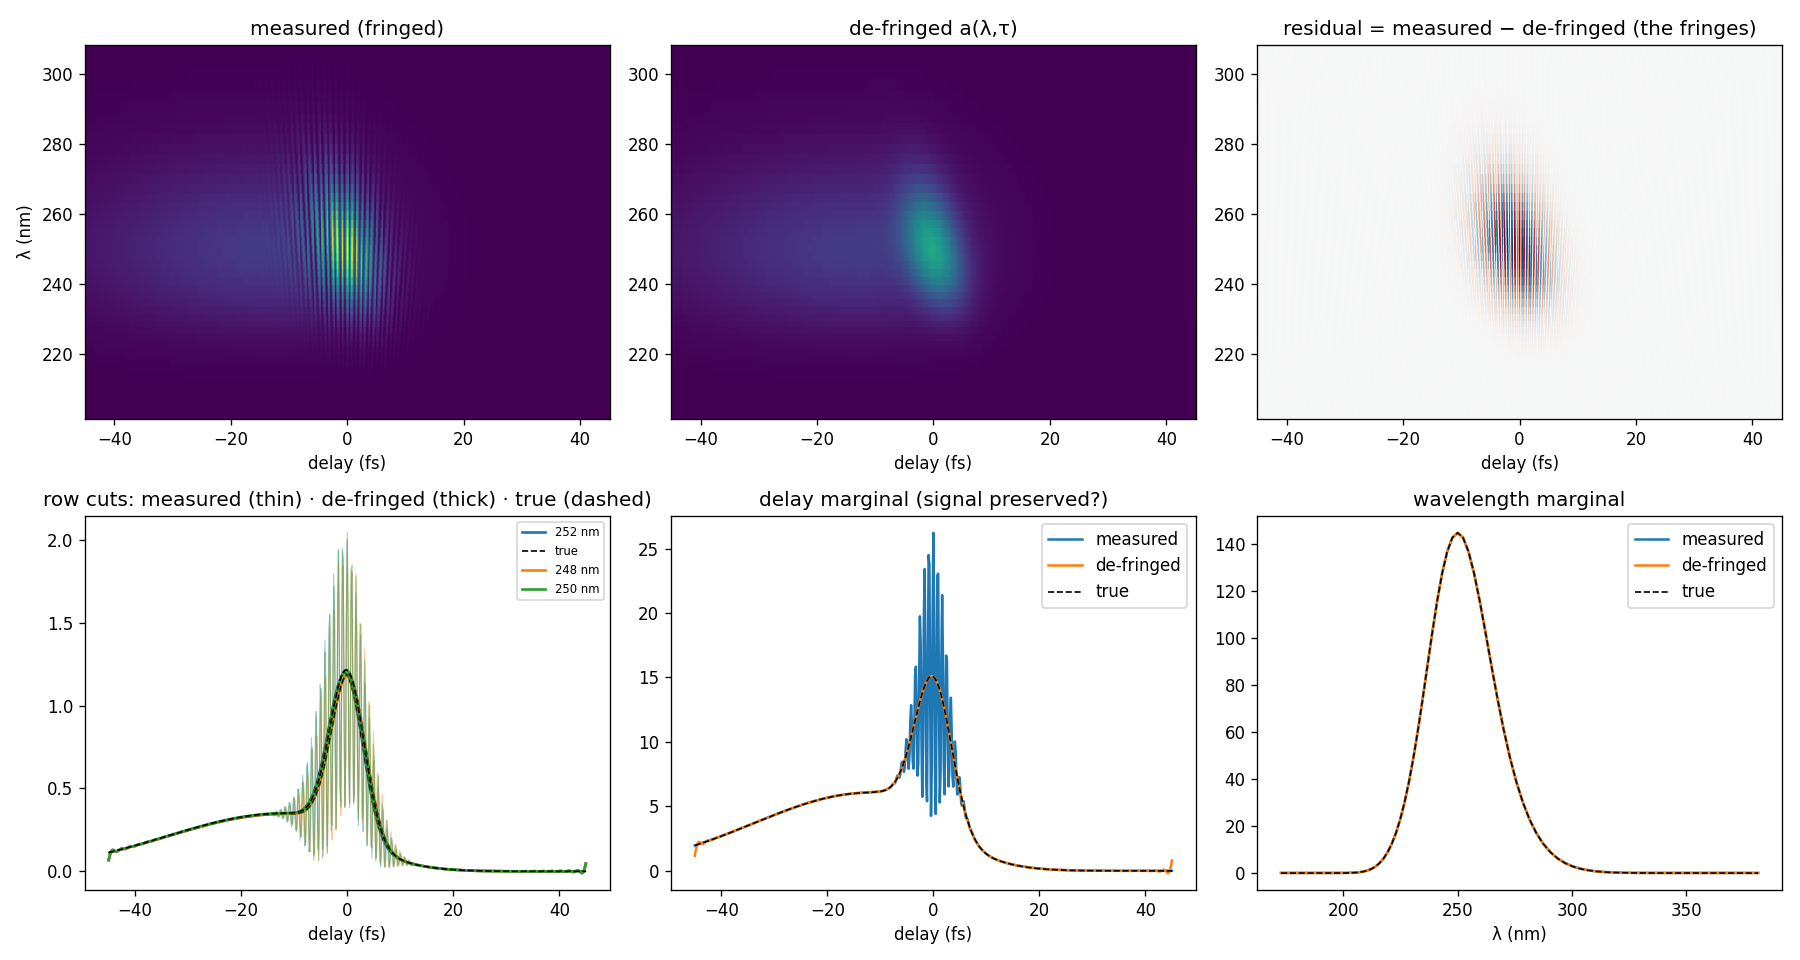

In [4]:
display(Image(filename="defringe_check.png"))